# Week 7 Lab 2: Bayes' Theorem and Distributions

Mathematics for Machine Learning, Session 2. 30 minutes, groups of 3.

## Before you start

1. `File > Save a copy in Drive`. Only the Driver needs to do this; the others follow on the shared screen.
2. None of the task cells is correct as given. Some crash, some run but give the wrong answer, some do both. Nobody will tell you where the problems are: that is the job.
3. Each task states what the right answer should be. Keep working on a cell until its last line prints `PASS`.
4. When a cell crashes, read the last line of the error first, then find the line it points to. The line it points to is not always where the mistake is.
5. Fix the code, do not rewrite the task. Do not edit the lines under `# check`.
6. Every cell runs on its own. If your group is stuck for more than 3 minutes, skip the task and come back.

## Roles

Rotate roles at the start of each Part.

- **Driver:** types and runs. Only types what the group agrees on.
- **Navigator:** reads the code aloud, line by line, and asks what each line should do.
- **Checker:** compares the output with the expected answer and the slides, and posts the group's answers in the main chat.

Discuss before anyone types. A fix nobody in the group can explain does not count.

| Part | Time | Driver | Navigator | Checker |
|---|---|---|---|---|
| 1. Monty Hall | 5 min | A | B | C |
| 2. Bayes' theorem | 10 min | B | C | A |
| 3. Covariance and correlation | 7 min | C | A | B |
| 4. Distributions | 8 min | A | B | C |

Everyone in the group must be able to explain every fix. One person from a random group will be asked to explain one.


## Group Members
1. Leon Nsamba
2. Michael Odhiambo
3. Daniel Gakumba Ntwali

## Part 1: Monty Hall (5 min)

Three doors (0, 1, 2), one car. You pick a door. The host knows where the car is and opens a different door with a goat behind it. You can stay or switch.

### Task 1.1

Staying should win about 1/3 of the games and switching about 2/3.

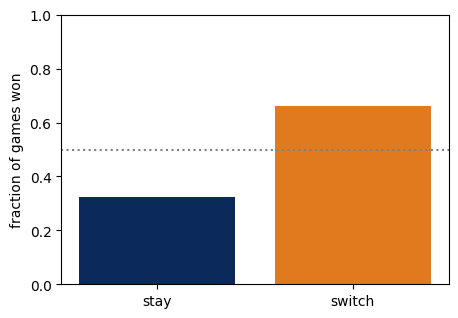

stay:   0.3256
switch: 0.6616
PASS | Monty Hall


In [19]:
# TASK 1.1
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(7)

def play(switch):
    car = rng.integers(3)
    pick = rng.integers(3)
    can_open = [d for d in range(3) if d != pick and d != car] # Added the !car condition
    host = rng.choice(can_open)
    if switch:
        pick = 3 - pick - host
    return pick == car

games = 10_000
win_stay = np.mean([play(switch=False) for _ in range(games)])
win_switch = np.mean([play(switch=True) for _ in range(games)])

plt.figure(figsize=(5, 3.5))
plt.bar(["stay", "switch"], [win_stay, win_switch], color=["#0B2A5B", "#E07A1F"])
plt.axhline(0.5, color="grey", linestyle=":")
plt.ylim(0, 1)
plt.ylabel("fraction of games won")
plt.show()

print("stay:  ", win_stay)
print("switch:", win_switch)

# check, do not edit
ok = abs(win_stay - 1/3) < 0.03 and abs(win_switch - 2/3) < 0.03
print("PASS" if ok else "NOT YET", "| Monty Hall")

Post your two win rates in the chat. Then discuss: with the bug, both strategies won about 1/3. Why does it matter that the host knows where the car is?

## Part 2: Bayes' theorem (10 min)

The fraud detector from the slides:

- 1% of transactions are fraud (prior)
- the model flags 90% of fraud (likelihood)
- it also flags 5% of honest transactions (false alarms)

A transaction is flagged. How likely is it to be fraud? About 15%.

### Task 2.1: count it

In [20]:
# TASK 2.1
import numpy as np
rng = np.random.default_rng(7)

n = 1_000_000
fraud = rng.random(n) < 0.01
flag = np.where(fraud, rng.random(n) < 0.90, rng.random(n) < 0.05)

print("fraud:", fraud.sum(), "| flagged:", flag.sum())

# Correcting the mean calculation
p_fraud_given_flag = fraud[flag].mean()

# check, do not edit
ok = abs(p_fraud_given_flag - 0.154) < 0.01
print("PASS" if ok else "NOT YET", f"| P(fraud | flag) = {p_fraud_given_flag:.3f}")

fraud: 9955 | flagged: 58291
PASS | P(fraud | flag) = 0.154


### Task 2.2: compute it

P(H | E) = P(E | H) P(H) / P(E), where P(E) = P(E | H) P(H) + P(E | not H) P(not H).



In [21]:
# TASK 2.2
def bayes_update(prior, p_e_given_h, p_e_given_not_h):
    evidence = p_e_given_h * prior + p_e_given_not_h * (1 - prior)
    return p_e_given_h * prior / evidence

# Adjusting the prior and p_e_given_h values which were initially wrong
# Editing/ correcting the p_e_given_not_h section
after_one_flag = bayes_update(prior=0.01, p_e_given_h=0.90, p_e_given_not_h=0.05)

# check, do not edit
ok = abs(after_one_flag - 0.1538) < 1e-3
print("PASS" if ok else "NOT YET", f"| P(fraud | one flag) = {after_one_flag:.4f}")

PASS | P(fraud | one flag) = 0.1538


### Task 2.3: update twice

A second, independent check also flags the transaction. The belief should go 1% to 15% to 77%.

In [22]:
# TASK 2.3
def bayes_update(prior, p_e_given_h, p_e_given_not_h):
    evidence = p_e_given_h * prior + p_e_given_not_h * (1 - prior)
    return p_e_given_h * prior / evidence

start = 0.01
after_one = bayes_update(start, 0.90, 0.05)
# Correcting to after_one which was initally start for the after_two
after_two = bayes_update(after_one, 0.90, 0.05)

print(f"start: {start:.3f}  one flag: {after_one:.3f}  two flags: {after_two:.3f}")

# check, do not edit
ok = abs(after_two - 0.766) < 1e-3
print("PASS" if ok else "NOT YET", f"| P(fraud | two flags) = {after_two:.3f}")

start: 0.010  one flag: 0.154  two flags: 0.766
PASS | P(fraud | two flags) = 0.766


### Task 2.4: a small spam filter

From the Session 1 inbox: P(spam) = 0.30, P("free" | spam) = 0.80, P("free" | not spam) = 0.10.

A second word: P("meeting" | spam) = 0.05, P("meeting" | not spam) = 0.40.

An email says "free" but does **not** say "meeting". Update once per word. P(spam) should end at about 0.84.

In [23]:
# TASK 2.4
def bayes_update(prior, p_e_given_h, p_e_given_not_h):
    evidence = p_e_given_h * prior + p_e_given_not_h * (1 - prior)
    return p_e_given_h * prior / evidence

p_spam = 0.30
p_spam = bayes_update(p_spam, 0.80, 0.10)
print(f'after "free":           {p_spam:.3f}')

# Correction of the values within the second update
p_spam = bayes_update(p_spam, 1 - 0.05, 1 - 0.40)
print(f'after no "meeting":     {p_spam:.3f}')

# check, do not edit
ok = abs(p_spam - 0.8445) < 1e-3
print("PASS" if ok else "NOT YET", f"| P(spam) = {p_spam:.3f}")

after "free":           0.774
after no "meeting":     0.844
PASS | P(spam) = 0.844


Discuss: the first number (0.774) should look familiar from Session 1. Where did you see it?

The value 0.774 is the posterior probability calculated using Bayes' Theorem, where we updated the prior probability of spam (0.30) after observing the word "free", using P(free | spam) = 0.80 and P (free | not spam) = 0.10

## Part 3: Covariance and correlation (7 min)

### Task 3.1: the covariance matrix by hand

The three students from the slides:

| Student | Math (X) | Science (Y) |
|---|---|---|
| 1 | 90 | 80 |
| 2 | 60 | 30 |
| 3 | 100 | 70 |

Expected: Var(X) = 433.3 and Cov(X, Y) = 500.

In [24]:
# TASK 3.1
import numpy as np

X = np.array([90, 60, 100])
Y = np.array([80, 30, 70])
n = len(X)

dx = X - X.mean()
dy = Y - Y.mean()

# Dividing by the n - 1 instead of just n
var_x = (dx * dx).sum() / (n - 1)
cov_xy = (dx * dy).sum() / (n - 1)

print("by hand: Var(X) =", round(var_x, 1), " Cov(X, Y) =", round(cov_xy, 1))
print(np.cov(X, Y))

# check, do not edit
ok = abs(var_x - 433.333) < 0.01 and abs(cov_xy - 500) < 0.01
print("PASS" if ok else "NOT YET", "| variance and covariance")

by hand: Var(X) = 433.3  Cov(X, Y) = 500.0
[[433.33333333 500.        ]
 [500.         700.        ]]
PASS | variance and covariance


### Task 3.2: from covariance to correlation

A covariance of 500 is hard to read because it depends on the units. Correlation rescales it to the range from -1 to 1:

corr(X, Y) = Cov(X, Y) / (σ_X σ_Y)

Expected: about 0.91, matching `np.corrcoef`.

In [25]:
# TASK 3.2
import numpy as np

X = np.array([90, 60, 100])
Y = np.array([80, 30, 70])

C = np.cov(X, Y)
var_x, var_y, cov_xy = C[0, 0], C[1, 1], C[0, 1]

# Changing to diving by the product of the standard deviations instead of variances
corr = cov_xy / np.sqrt(var_x * var_y)

print("by hand:", round(corr, 3))
print("NumPy:  ", round(np.corrcoef(X, Y)[0, 1], 3))

# check, do not edit
ok = abs(corr - 0.9078) < 1e-3
print("PASS" if ok else "NOT YET", f"| correlation = {corr:.4f}")

by hand: 0.908
NumPy:   0.908
PASS | correlation = 0.9078


### Task 3.3: tilt the cloud

A 2-D Gaussian has a mean vector and a covariance matrix. Make the cloud lean up to the right, like the slide.

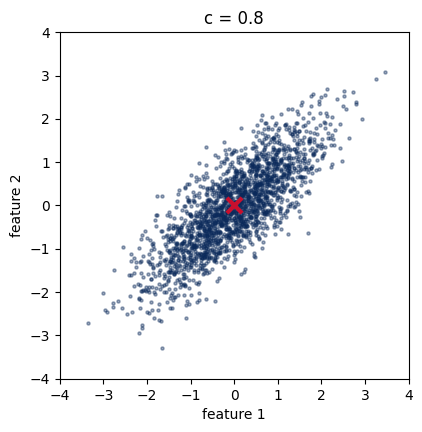

covariance from the points: 0.77
PASS | tilt of the cloud


In [26]:
# TASK 3.3
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(7)

# Changing the c from -0.8 to 0.8
c = 0.8

mean = [0, 0]
cov = [[1, c],
       [c, 1]]
points = rng.multivariate_normal(mean, cov, size=2_000)

plt.figure(figsize=(4.5, 4.5))
plt.scatter(points[:, 0], points[:, 1], s=5, alpha=0.4, color="#0B2A5B")
plt.scatter([0], [0], color="#C8102E", marker="x", s=120, linewidths=3)
plt.xlim(-4, 4)
plt.ylim(-4, 4)
plt.xlabel("feature 1")
plt.ylabel("feature 2")
plt.title(f"c = {c}")
plt.show()

sample_cov = np.cov(points.T)[0, 1]
print("covariance from the points:", round(sample_cov, 2))

# check, do not edit
ok = sample_cov > 0.5
print("PASS" if ok else "NOT YET", "| tilt of the cloud")

After it passes, try `c = 0`. What shape is the cloud?

When c = 0, the cloud looks circular with randomly scattered cluster of points

## Part 4: Distributions (8 min)

Reproduce the answers from the group presentations by sampling.

### Task 4.1: binomial

10 visits, each converts with probability 0.3. P(exactly 2 convert) = 0.233.

In [27]:
# TASK 4.1
import numpy as np
rng = np.random.default_rng(7)

conversions = rng.binomial(n=10, p=0.3, size=200_000)
print(conversions[:20])

# Changing for conversions >=2 to conversions == 2
p_two = (conversions == 2).mean()

# check, do not edit
ok = abs(p_two - 0.2335) < 0.006
print("PASS" if ok else "NOT YET", f"| P(exactly 2) = {p_two:.3f}")

[3 5 4 2 2 5 0 4 4 3 2 2 2 3 3 3 7 4 3 6]
PASS | P(exactly 2) = 0.234


### Task 4.2: Poisson

A server gets 5 requests per second on average. P(exactly 3 requests in a second) = 0.140.

In [28]:
# TASK 4.2
import numpy as np
rng = np.random.default_rng(7)

# Changing the lam to be 5 instead of 3
requests = rng.poisson(lam=5, size=200_000)
# Chaning the request number to 3 from 5
p_three = (requests == 3).mean()

print("average per second:", requests.mean())

# check, do not edit
ok = abs(p_three - 0.1404) < 0.006
print("PASS" if ok else "NOT YET", f"| P(exactly 3) = {p_three:.3f}")

average per second: 4.99618
PASS | P(exactly 3) = 0.141


### Task 4.3: exponential

Same server, 5 requests per second. The gap between two requests is exponential with rate λ = 5, so the mean gap is 1/5 second.

P(the next request takes more than 0.5 seconds) = e^(-5 × 0.5) = 0.082.

In [29]:
# TASK 4.3
import numpy as np
rng = np.random.default_rng(7)

lam = 5
# Correction of the lam referncing
gaps = rng.exponential(scale=1/lam, size=200_000)

print("mean gap:", round(gaps.mean(), 3), "seconds")
p_long = (gaps > 0.5).mean()

# check, do not edit
ok = abs(p_long - 0.0821) < 0.005
print("PASS" if ok else "NOT YET", f"| P(gap > 0.5 s) = {p_long:.3f}")

mean gap: 0.2 seconds
PASS | P(gap > 0.5 s) = 0.082


### Task 4.4: Gaussian

Exam scores have mean 65 and standard deviation 10. About 95% of scores should fall within 2 standard deviations, between 45 and 85.

In [30]:
# TASK 4.4
import numpy as np
rng = np.random.default_rng(7)

mu, sigma = 65, 10
# Correcting the size
scores = rng.normal(loc=mu, scale=sigma, size=200_000)

print("sample std:", round(scores.std(), 1))
within = ((scores > 45) & (scores < 85)).mean()

# check, do not edit
ok = abs(within - 0.9545) < 0.006
print("PASS" if ok else "NOT YET", f"| within 2 sd = {within:.3f}")

sample std: 10.0
PASS | within 2 sd = 0.954


**Exit ticket, post in the chat:** which distribution fits *the number of typos on a page*, and why? One sentence per group.

## Stretch: Monty Hall with Bayes' theorem

You picked door 1. The host opened door 3. The car is behind door 1, 2 or 3, each with prior 1/3.

The likelihood is P(host opens door 3 | car's position). Think about what the host is allowed to do in each case. The posterior for door 2 should be 2/3.

In [31]:
# TASK S
import numpy as np

prior = np.array([1/3, 1/3, 1/3])
# Correction of the likelihood
likelihood = np.array([1/2, 1, 0])

evidence = (likelihood * prior).sum()
posterior = likelihood * prior / evidence

for door, p in zip([1, 2, 3], posterior):
    print(f"door {door}: {p:.3f}")

# check, do not edit
ok = abs(posterior[1] - 2/3) < 1e-9
print("PASS" if ok else "NOT YET", "| posterior for door 2")

door 1: 0.333
door 2: 0.667
door 3: 0.000
PASS | posterior for door 2
